# Modernized 2D Elastoplastic BEM (ELQUABE-EP2D)


This repository contains a modernized Fortran 90 implementation of the **2D Elastoplastic Boundary Element Method (BEM)**, combining the quadratic boundary element architecture of **ELQUABE** (*Brebbia & Dominguez, 1992*) with the 2D initial-stress elastoplastic domain-cell formulation of **BEMECH** (*Gao & Davies, 2001*).

The solver models two-dimensional (**Plane Strain** and **Plane Stress**) elastic and elastoplastic problems using 3-node quadratic boundary elements (`line3`) and 6-node triangular (`triangle6`) or 8-node serendipity quadrilateral (`quad8`) internal cells.

# Download `ELQUABE-EP2D` from `Github`

In [ ]:
!git clone https://github.com/e-albuquerque/BEM2D-Elastoplasticity-ELQUABE.git

Cloning into 'BEM2D-Elastoplasticity-ELQUABE'...
remote: Enumerating objects: 194, done.
remote: Counting objects: 100% (194/194), done.
remote: Compressing objects: 100% (112/112), done.
remote: Total 194 (delta 82), reused 194 (delta 82), pack-reused 0 (from 0)
Receiving objects: 100% (194/194), 10.18 MiB | 26.25 MiB/s, done.
Resolving deltas: 100% (82/82), done.


In [ ]:
ls

BEM2D-Elastoplasticity-ELQUABE/  sample_data/


In [ ]:
cd BEM2D-Elastoplasticity-ELQUABE/

/content/BEM2D-Elastoplasticity-ELQUABE


In [ ]:
ls

assembly_mod.f90                eq12cb.out     plastic_strain_map.png
build.bat                       fluxogram.py   posproc.py
cylinder_analytical_results.py  geometry.png   preproc.py
data_mod.f90                    input_data.py  README.md
diagrama_graphviz.png           io_mod.f90     resultado_elquabe.vtk
diagrama_nl_graphviz.png        main.f90       result_plot.png
displacement_map.png            Makefile       Run_elquabe_on_Colab.ipynb
dpbou.dat                       placa2.geo     solver_mod.f90
dpint.dat                       placa2.msh     stbou.dat
elquabe.for                     placa.geo      stint.dat
eq12cb.dat                      placa.msh      von_mises_map.png


# Compile the code ```elquabe_modern.for```

In [ ]:
!make

gfortran -fopenmp -O3 -fdefault-real-8 -Wall -Wextra -c data_mod.f90
gfortran -fopenmp -O3 -fdefault-real-8 -Wall -Wextra -c io_mod.f90
gfortran -fopenmp -O3 -fdefault-real-8 -Wall -Wextra -c solver_mod.f90
gfortran -fopenmp -O3 -fdefault-real-8 -Wall -Wextra -c assembly_mod.f90
gfortran -fopenmp -O3 -fdefault-real-8 -Wall -Wextra -c main.f90
gfortran -fopenmp -O3 -fdefault-real-8 -Wall -Wextra  -o elquabe_modern.exe data_mod.o io_mod.o solver_mod.o assembly_mod.o main.o -llapack -lblas


In [ ]:
ls

assembly_mod.f90                eq12cb.dat     plastic_strain_map.png
assembly_mod.mod                eq12cb.out     posproc.py
assembly_mod.o                  fluxogram.py   preproc.py
build.bat                       geometry.png   README.md
cylinder_analytical_results.py  input_data.py  resultado_elquabe.vtk
data_mod.f90                    io_mod.f90     result_plot.png
data_mod.mod                    io_mod.mod     Run_elquabe_on_Colab.ipynb
data_mod.o                      io_mod.o       solver_mod.f90
diagrama_graphviz.png           main.f90       solver_mod.mod
diagrama_nl_graphviz.png        main.o         solver_mod.o
displacement_map.png            Makefile       stbou.dat
dpbou.dat                       placa2.geo     stint.dat
dpint.dat                       placa2.msh     von_mises_map.png
elquabe.for                     placa.geo
elquabe_modern.exe*             placa.msh


# Install `gmsh`

In [ ]:
!apt-get update
!apt-get install gmsh
!python -m pip install gmsh

Get:1 https://cli.github.com/packages stable InRelease [3,917 B]
Get:2 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease [3,631 B]
Get:3 https://r2u.stat.illinois.edu/ubuntu noble InRelease [9,161 B]
Get:4 https://cli.github.com/packages stable/main amd64 Packages [357 B]
Get:5 http://security.ubuntu.com/ubuntu noble-security InRelease [126 kB]
Hit:6 http://archive.ubuntu.com/ubuntu noble InRelease
Get:7 http://archive.ubuntu.com/ubuntu noble-updates InRelease [126 kB]
Get:8 https://r2u.stat.illinois.edu/ubuntu noble/main all Packages [10.5 MB]
Get:9 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease [17.8 kB]
Get:10 https://r2u.stat.illinois.edu/ubuntu noble/main amd64 Packages [3,097 kB]
Get:11 http://archive.ubuntu.com/ubuntu noble-backports InRelease [126 kB]
Get:12 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble/main amd64 Packages [60.0 kB]
Get:13 http://archive.ubuntu.com/ubuntu noble-updates/main amd64 Packages [1,739 kB]
Get:

# Install `meshio`

In [ ]:
!pip install meshio[all]

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.6/10.6 MB 71.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 35.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [meshio]


# Gmsh geometry file (`.geo`)

In [ ]:
%%writefile placa.geo
ref=0.1;
Point(1) = {0, 0, 0, ref};
Point(2) = {1, 0, 0, ref};
Point(3) = {1.5, 0, 0, ref};
Point(4) = {0, 1.5, 0, ref};
Point(5) = {0, 1, 0, ref};
Line(1) = {2, 3};
Circle(2) = {3, 1, 4};
Line(3) = {4, 5};
Circle(4) = {5, 1, 2};
Line loop(1) = {1,2,3,4};
Plane Surface(1) = {1};
Physical Curve("fix1") = {1};
Physical Curve("fix2") = {3};
Physical Curve("loaded") = {4};
Physical Curve("free") = {2};
Physical Surface("surf1") = {1};

Overwriting placa.geo


# Generate mesh file (`.msh`) using Gmsh

In [ ]:
!gmsh -2  placa.geo -o placa.msh  -order 2

Info    : Running '/usr/local/bin/gmsh -2 placa.geo -o placa.msh -order 2' [Gmsh 4.15.2, 1 node, max. 1 thread]
Info    : Started on Wed Oct 28 12:48:42 2026
Info    : Reading 'placa.geo'...
Info    : Done reading 'placa.geo'
Info    : Meshing 1D...
Info    : [  0%] Meshing curve 1 (Line)
Info    : [ 30%] Meshing curve 2 (Circle)
Info    : [ 60%] Meshing curve 3 (Line)
Info    : [ 80%] Meshing curve 4 (Circle)
Info    : Done meshing 1D (Wall 0.00062243s, CPU 0.000616s)
Info    : Meshing 2D...
Info    : Meshing surface 1 (Plane, Frontal-Delaunay)
Info    : Done meshing 2D (Wall 0.00621696s, CPU 0.008123s)
Info    : Meshing order 2 (curvilinear on)...
Info    : [  0%] Meshing curve 1 order 2
Info    : [ 30%] Meshing curve 2 order 2
Info    : [ 50%] Meshing curve 3 order 2
Info    : [ 70%] Meshing curve 4 order 2
Info    : [ 90%] Meshing surface 1 order 2
Info    : Surface mesh: worst distortion = 0.953584 (0 elements in ]0, 0.2]); worst gamma = 0.842896
Info    : Done meshing order 2 (Wa

# Input data

In [ ]:
%%writefile input_data.py
def input_data(problem=1):
    """
    Defines input parameters for the 2D Elastoplastic Boundary Element Method (BEM)
    simulation using continuous quadratic boundary elements and quadratic internal
    cells (6-node triangles or 8-node quadrilaterals).

    Available problems:
        1 : Quarter thick-walled cylinder under internal pressure (placa.geo / placa.msh)
        2 : Square plate under uniaxial traction (placa2.geo / placa2.msh)

    Boundary condition types in `bound_cond`:
        * type_x, type_y = 0 : Prescribed displacement in global x or y direction
        * type_x, type_y = 1 : Prescribed traction in global x or y direction
        * type_x = 2         : Prescribed normal traction/pressure (value_x = t_n);
                               decomposed into global (t_x, t_y) components in preproc.py

    Plasticity parameters in `plasticity`:
        * nsig  : Number of stress components (4 = Plane Strain, 3 = Plane Stress)
        * tolgp : Gauss integration tolerance for internal cells
        * nauto : Gauss integration control (<0: adaptive sub-cells with |nauto| singular points)
        * ncrit : Yield criterion (1 = Tresca, 2 = von Mises, 3 = Mohr-Coulomb, 4 = Drucker-Prager)
        * uniax : Uniaxial yield stress (sigma_Y)
        * frict : Friction angle in degrees (for Mohr-Coulomb / Drucker-Prager)
        * hardi : Isotropic plastic hardening modulus (H')
        * hardk : Kinematic plastic hardening modulus
        * em    : Mixed hardening parameter (1.0 = isotropic, 0.0 = kinematic)
        * nincs : Number of load increments (0 = automatic default from BEM solver)
        * fincr : Load increment scaling factor
        * miter : Maximum iterations per load increment
        * toler : Convergence tolerance for plastic multiplier iterations
    """
    # Select which problem to run (1 = Cylinder under internal pressure, 2 = Plate under traction)
    selected_problem = problem

    if selected_problem == 1:
        # Problem 1: One-quarter thick cylinder under internal pressure (Elastoplastic)
        # Symmetry at y = 0 ('fix1'): t_x = 0 (type_x = 1), u_y = 0 (type_y = 0)
        # Symmetry at x = 0 ('fix2'): u_x = 0 (type_x = 0), t_y = 0 (type_y = 1)
        # Outer radius r = b ('free'): traction-free (t_x = 0, t_y = 0)
        # Inner radius r = a ('loaded'): normal internal pressure (type_x = 2, value_x = -10.0)
        bound_cond = {
            'fix1':   {'type_x': 1, 'value_x': 0.0,   'type_y': 0, 'value_y': 0.0},
            'fix2':   {'type_x': 0, 'value_x': 0.0,   'type_y': 1, 'value_y': 0.0},
            'free':   {'type_x': 1, 'value_x': 0.0,   'type_y': 1, 'value_y': 0.0},
            'loaded': {'type_x': 2, 'value_x': -10.0, 'type_y': 0, 'value_y': 0.0},
        }
        E = 70.0e9
        nu = 0.3
        file_name = 'placa'
        title = 'ELASTOPLASTIC CYLINDER UNDER INTERNAL PRESSURE'
        problem_type = 'cylinder'
        plasticity = {
            'nsig':  4,        # Plane strain
            'tolgp': 1.0e-5,   # Gauss integration tolerance
            'nauto': -6,       # Adaptive cell integration (6 Gauss points for singular integrals)
            'ncrit': 2,        # von Mises yield criterion
            'uniax': 24.0,     # Yield stress sigma_Y (elastic max sigma_eq at r=a is ~31.34)
            'frict': 0.0,      # Friction angle (degrees)
            'hardi': 0.0,      # Perfectly plastic (H' = 0)
            'hardk': 0.0,      # Kinematic hardening modulus
            'em':    1.0,      # Purely isotropic factor
            'nincs': 0,        # 0 = automatic number of increments
            'fincr': 0.95,     # Increment progression factor
            'miter': 50,       # Max plastic iterations per increment
            'toler': 1.0e-5,   # Plastic convergence tolerance
        }
        analytical_params = {
            'a': 1.0,
            'b': 1.5,
            'pressure': 10.0,
            'yield_stress': plasticity['uniax'],
            'ncrit': plasticity['ncrit'],
            'hardi': plasticity['hardi'],
        }

    elif selected_problem == 2:
        # Problem 2: Square plate under uniaxial vertical traction
        bound_cond = {
            'botton': {'type_x': 0, 'value_x': 0.0, 'type_y': 0, 'value_y': 0.0},
            'right':  {'type_x': 1, 'value_x': 0.0, 'type_y': 1, 'value_y': 0.0},
            'top':    {'type_x': 1, 'value_x': 0.0, 'type_y': 1, 'value_y': 1.0},
            'left':   {'type_x': 1, 'value_x': 0.0, 'type_y': 1, 'value_y': 0.0},
        }
        E = 1.0
        nu = 0.0
        file_name = 'placa2'
        title = 'SQUARE PLATE UNDER UNIAXIAL TRACTION'
        problem_type = 'plate'
        plasticity = {
            'nsig':  4,
            'tolgp': 1.0e-5,
            'nauto': -6,
            'ncrit': 2,
            'uniax': 0.8,
            'frict': 0.0,
            'hardi': 0.2,
            'hardk': 0.0,
            'em':    1.0,
            'nincs': 0,
            'fincr': 0.95,
            'miter': 50,
            'toler': 1.0e-5,
        }
        analytical_params = {
            'traction_y': 1.0,
            'yield_stress': plasticity['uniax'],
            'hardi': plasticity['hardi'],
        }

    else:
        raise ValueError(f"Unknown problem selection: {selected_problem}. Choose 1 or 2.")

    return {
        'problem': selected_problem,
        'problem_type': problem_type,
        'title': title,
        'bound_cond': bound_cond,
        'E': E,
        'nu': nu,
        'file_name': file_name,
        'plasticity': plasticity,
        'analytical_params': analytical_params,
    }


Overwriting input_data.py


# Run `preproc.py`

In [ ]:
!python preproc.py


Geometry plot saved to 'geometry.png'.
Input file 'eq12cb.dat' generated successfully (NE=50, L=459, NCELL=254, NODC=6).


# Show Geometry and boundary conditions

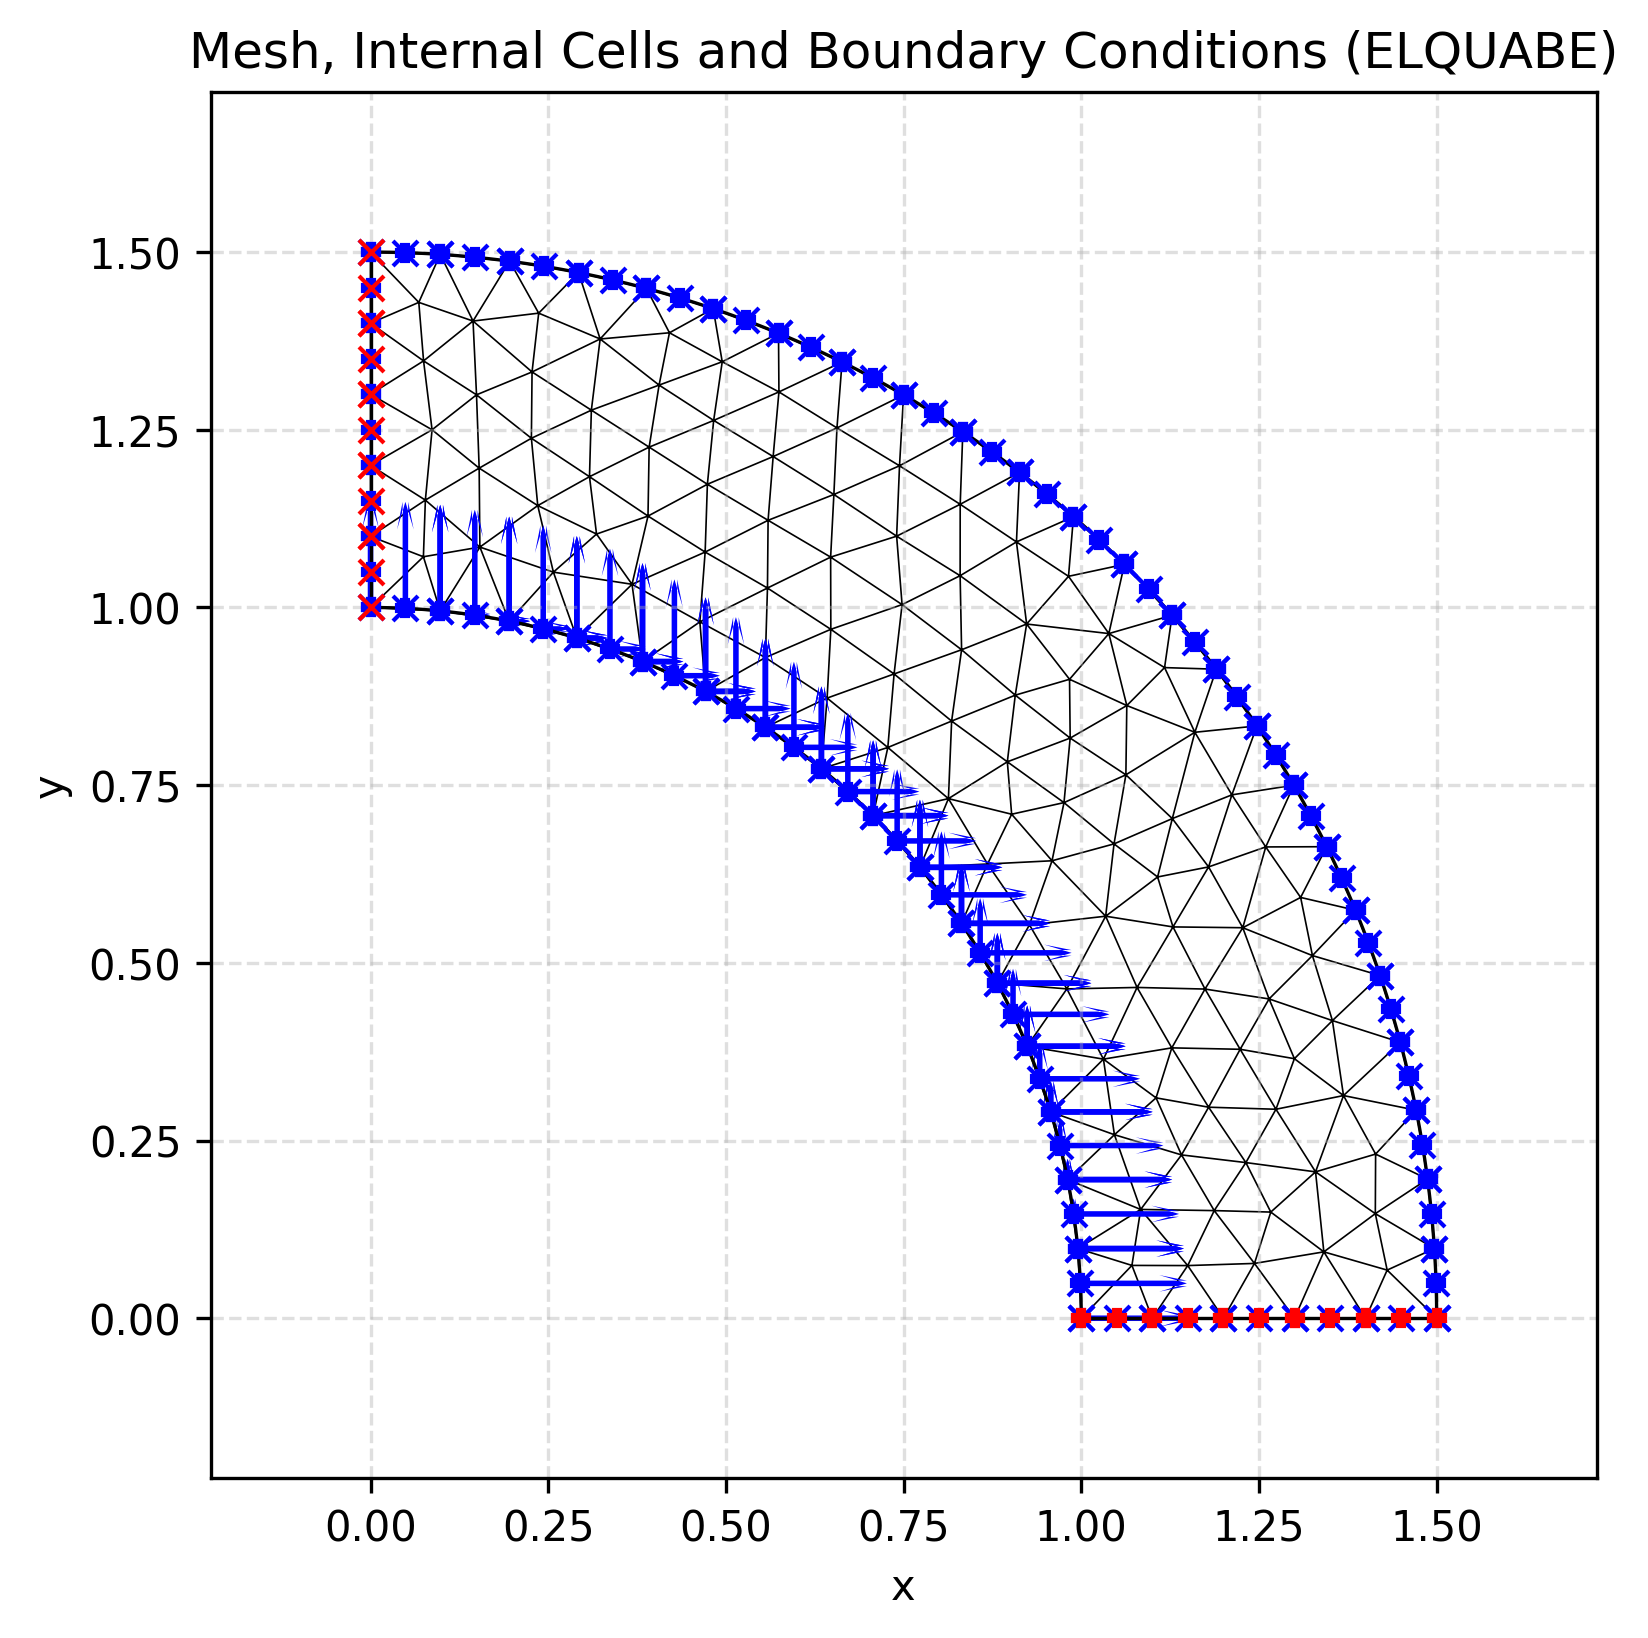

In [ ]:
from IPython.display import Image
Image('geometry.png', width=500)

# Run `elquabe_modern.exe`

In [ ]:
!./elquabe_modern.exe


          Forming 2D PLASTIC Coefficient Matrices (NCELL= 254, NODC= 6)...

          Solving 2D Non-Linear Elastoplastic System Equations...

  STRESS LIMIT ==  2.400000E+01     MAXIMUM EQU. STRESS ==  3.134166E+01
     RERR ==  9.677947E-02,  NYIELD ==  33,  ITER ==  1,  INCREM ==   1
     RERR ==  2.966810E-04,  NYIELD ==  33,  ITER ==  2,  INCREM ==   1
     RERR ==  9.188916E-07,  NYIELD ==  33,  ITER ==  3,  INCREM ==   1
     RERR ==  9.230274E-02,  NYIELD ==  33,  ITER ==  1,  INCREM ==   2
     RERR ==  2.567452E-04,  NYIELD ==  33,  ITER ==  2,  INCREM ==   2
     RERR ==  7.400103E-07,  NYIELD ==  33,  ITER ==  3,  INCREM ==   2
     RERR ==  8.768301E-02,  NYIELD ==  33,  ITER ==  1,  INCREM ==   3
     RERR ==  2.223753E-04,  NYIELD ==  33,  ITER ==  2,  INCREM ==   3
     RERR ==  5.988672E-07,  NYIELD ==  33,  ITER ==  3,  INCREM ==   3
     RERR ==  9.607122E-02,  NYIELD ==  67,  ITER ==  1,  INCREM ==   4
     RERR ==  3.441781E-04,  NYIELD ==  67,  ITER ==  2,  INCRE

In [ ]:
ls

assembly_mod.f90                eq12cb.dat     plastic_strain_map.png
assembly_mod.mod                eq12cb.out     posproc.py
assembly_mod.o                  fluxogram.py   preproc.py
build.bat                       geometry.png   __pycache__/
cylinder_analytical_results.py  input_data.py  README.md
data_mod.f90                    io_mod.f90     resultado_elquabe.vtk
data_mod.mod                    io_mod.mod     result_plot.png
data_mod.o                      io_mod.o       Run_elquabe_on_Colab.ipynb
diagrama_graphviz.png           main.f90       solver_mod.f90
diagrama_nl_graphviz.png        main.o         solver_mod.mod
displacement_map.png            Makefile       solver_mod.o
dpbou.dat                       placa2.geo     stbou.dat
dpint.dat                       placa2.msh     stint.dat
elquabe.for                     placa.geo      von_mises_map.png
elquabe_modern.exe*             placa.msh


# Run `posproc.py`

In [ ]:
!python posproc.py

ELQUABE 2D ELASTOPLASTIC VALIDATION SUMMARY (CYLINDER UNDER INTERNAL PRESSURE)
Inner Radius a = 1.000 m, Outer Radius b = 1.500 m, Pressure P = 10.00 Pa
Yield Stress sigma_Y = 24.00 Pa, Analytical Plastic Radius c = 1.2015 m
--------------------------------------------------------------------------------
Relative L2 Error in Radial Displacement u_r        : 4.4398e-03 (0.44%)
Relative L2 Error in Radial Stress sigma_r          : 4.7723e-03 (0.48%)
Relative L2 Error in Hoop Stress sigma_theta        : 5.8277e-03 (0.58%)
Relative L2 Error in von Mises Stress sigma_vM      : 3.4501e-03 (0.35%)
Max Equivalent Plastic Strain (BEM vs. Analytical)  : 1.8322e-10 vs. 1.7808e-10
Validation plot saved to 'result_plot.png'.

VTK file 'resultado_elquabe.vtk' saved successfully.
Displacement contour map 'displacement_map.png' saved successfully.
von Mises contour map 'von_mises_map.png' saved successfully.
Plastic strain contour map 'plastic_strain_map.png' saved successfully.


# Show von Mises equivalent stress

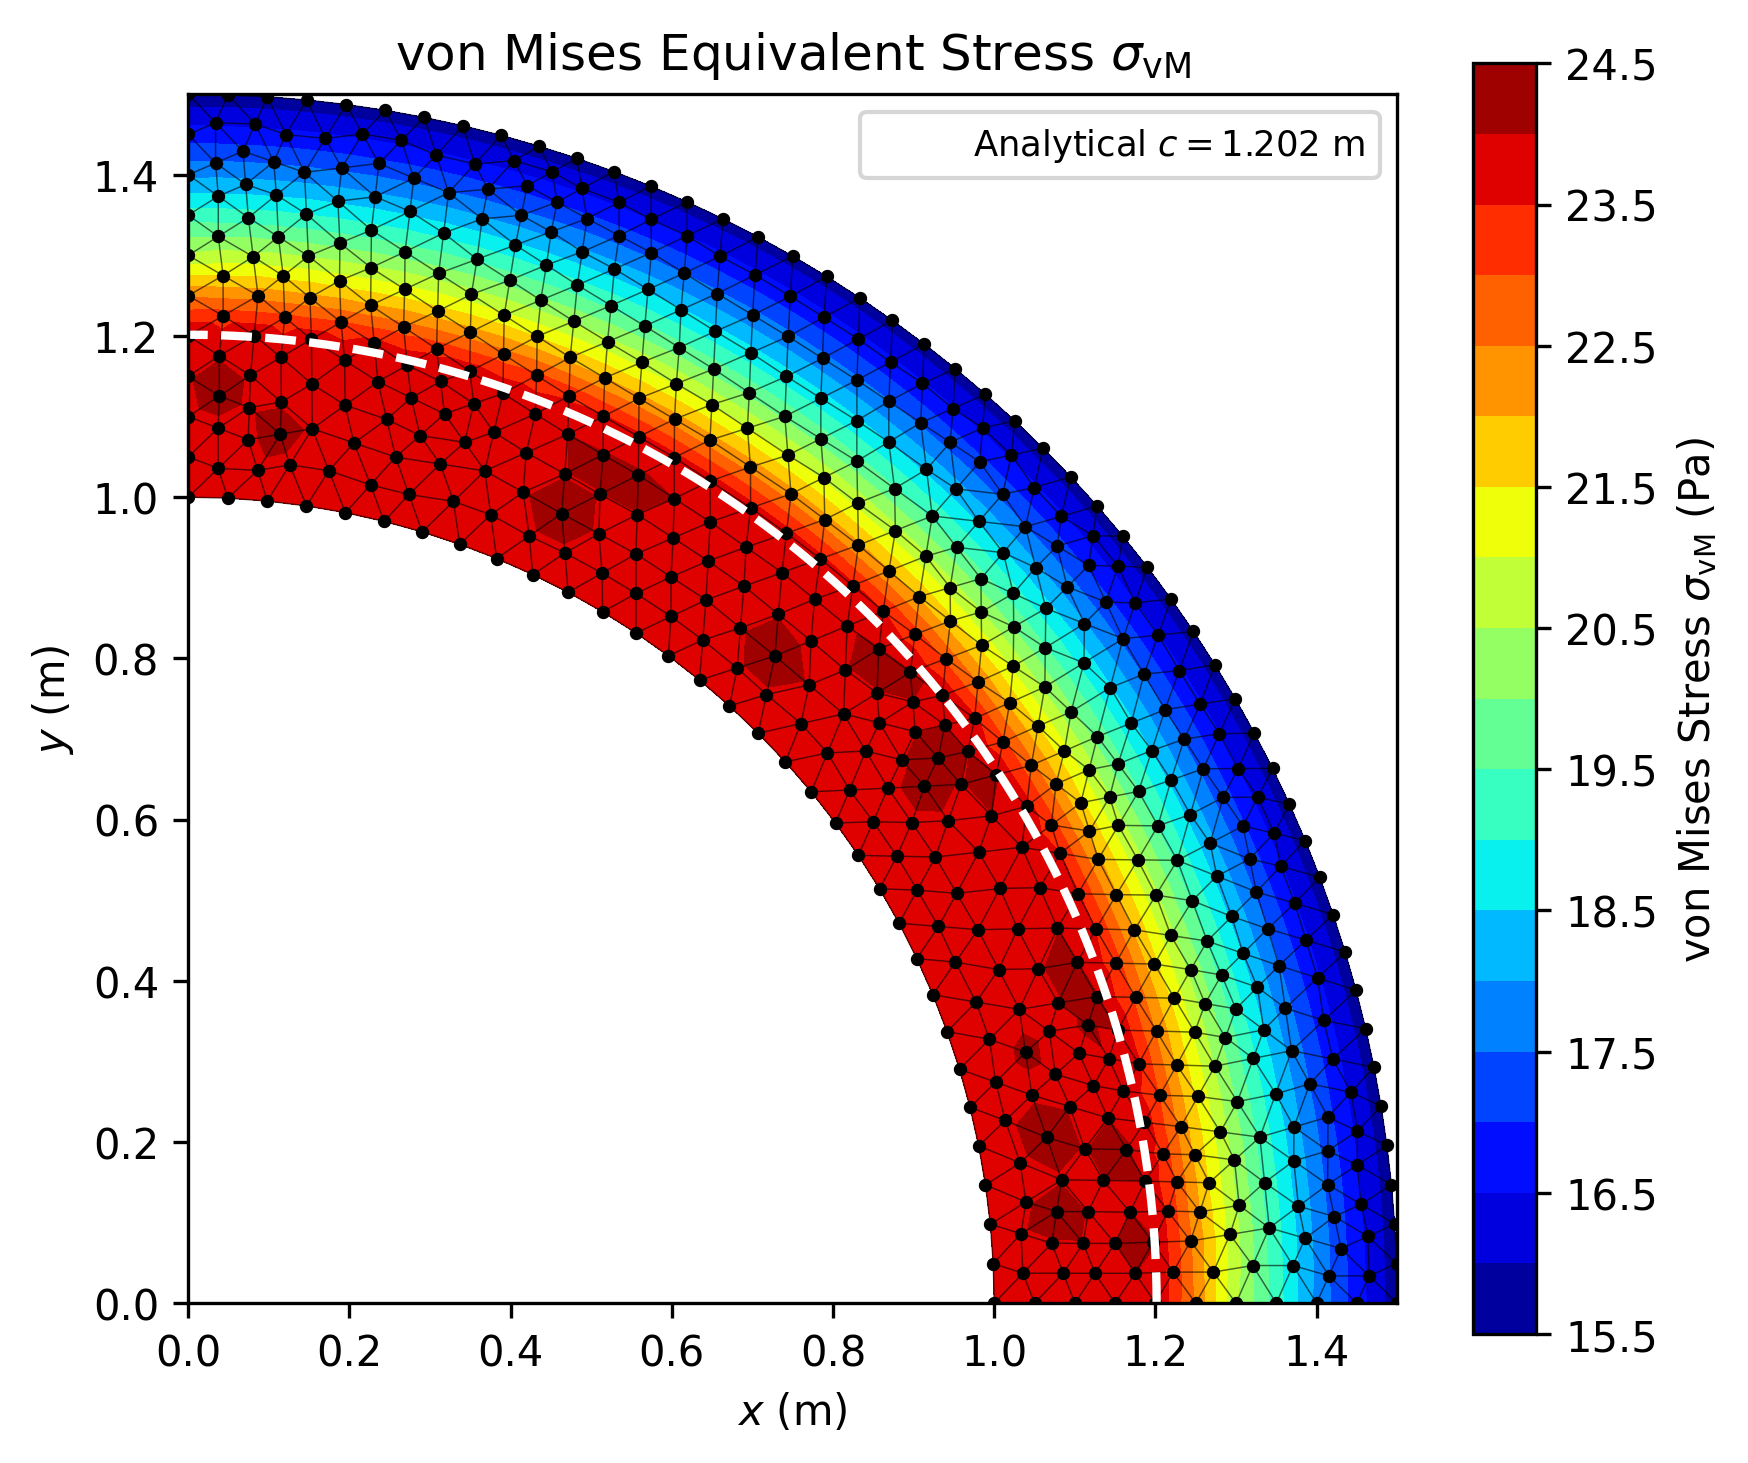

In [ ]:
from IPython.display import Image
Image('von_mises_map.png', width=500)

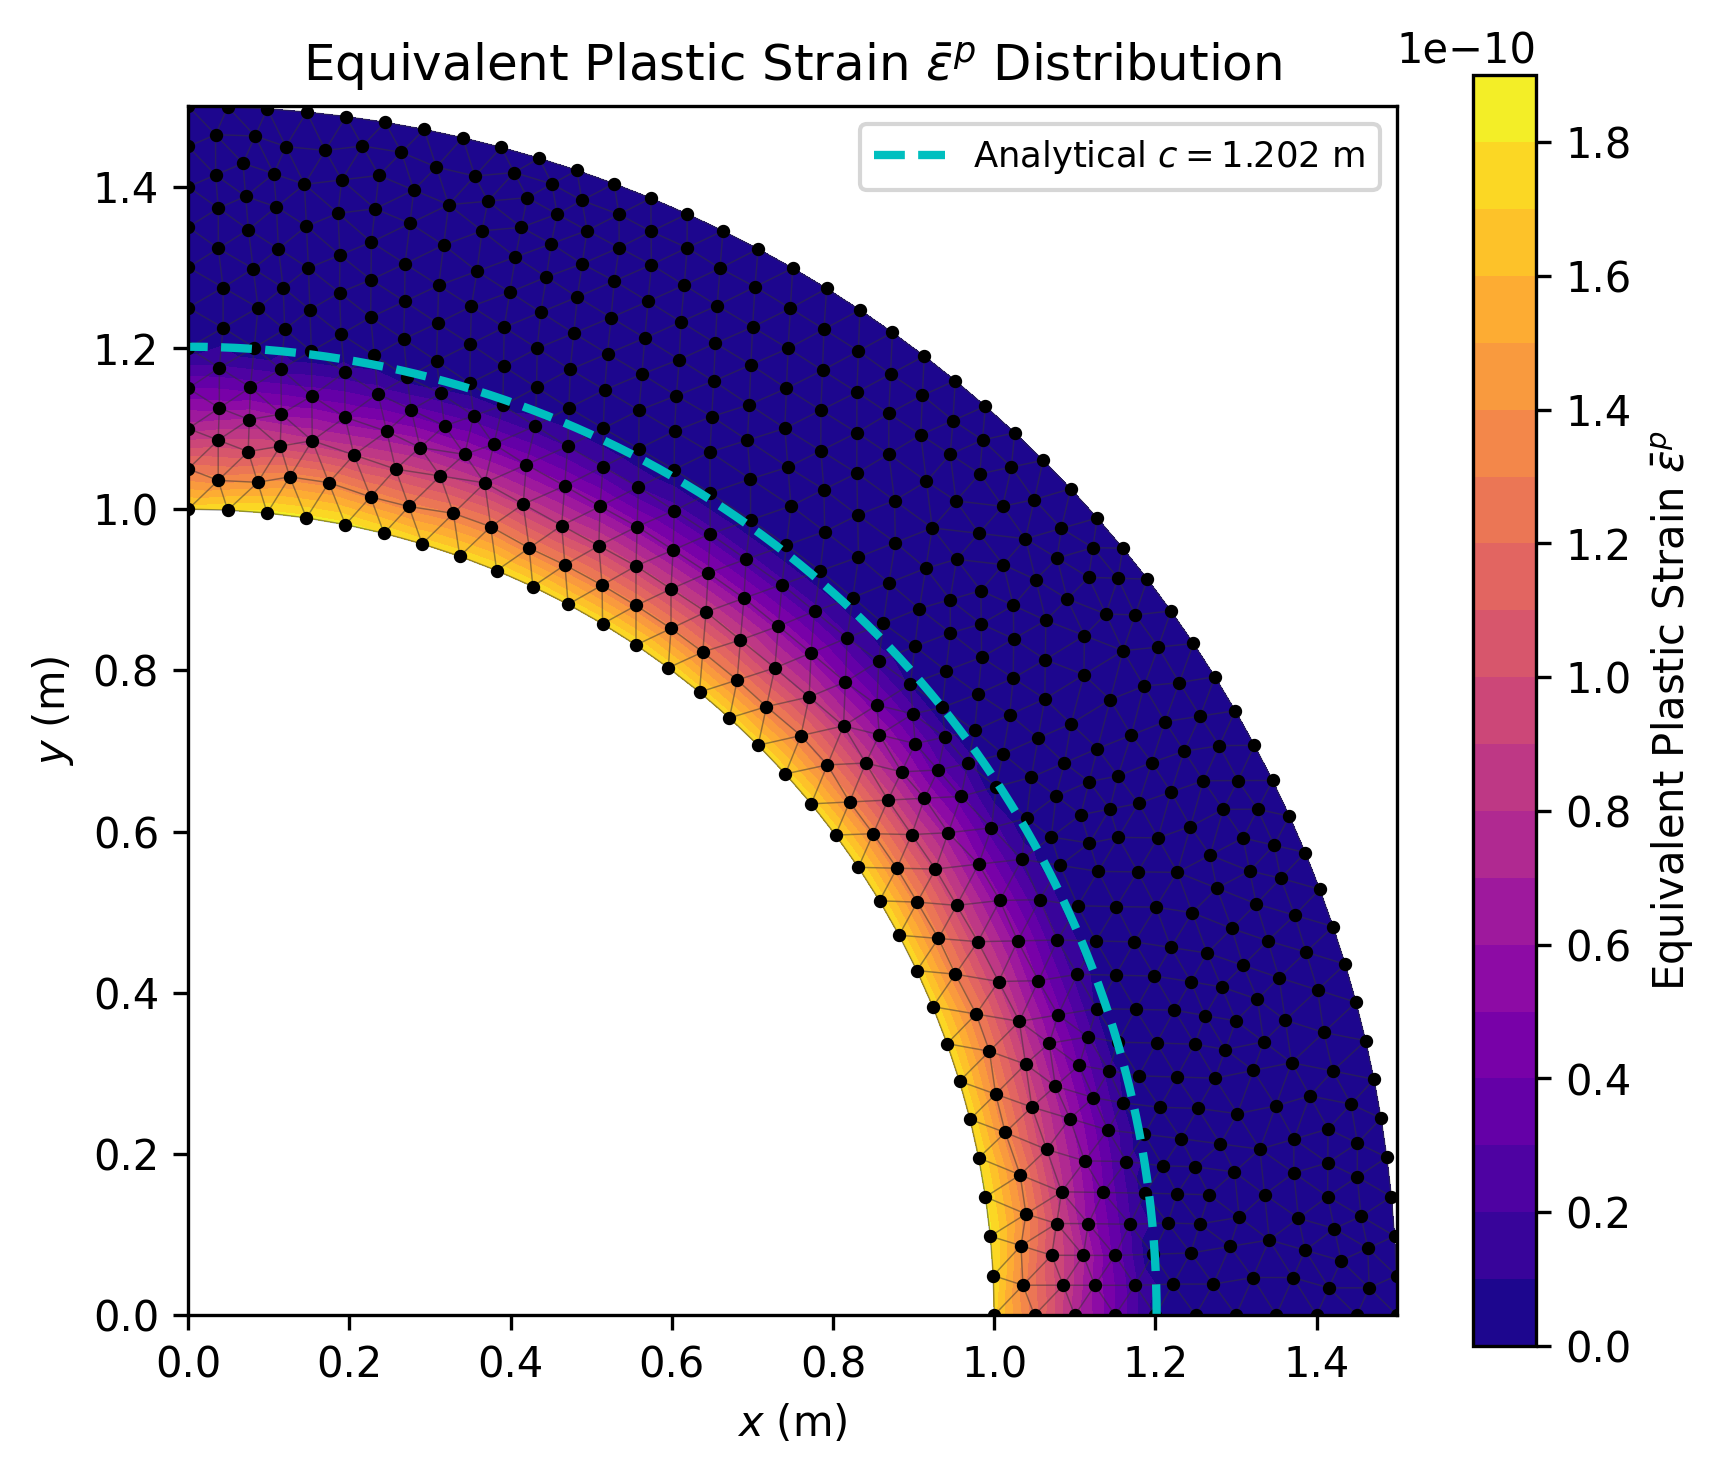

In [ ]:
from IPython.display import Image
Image('plastic_strain_map.png', width=500)

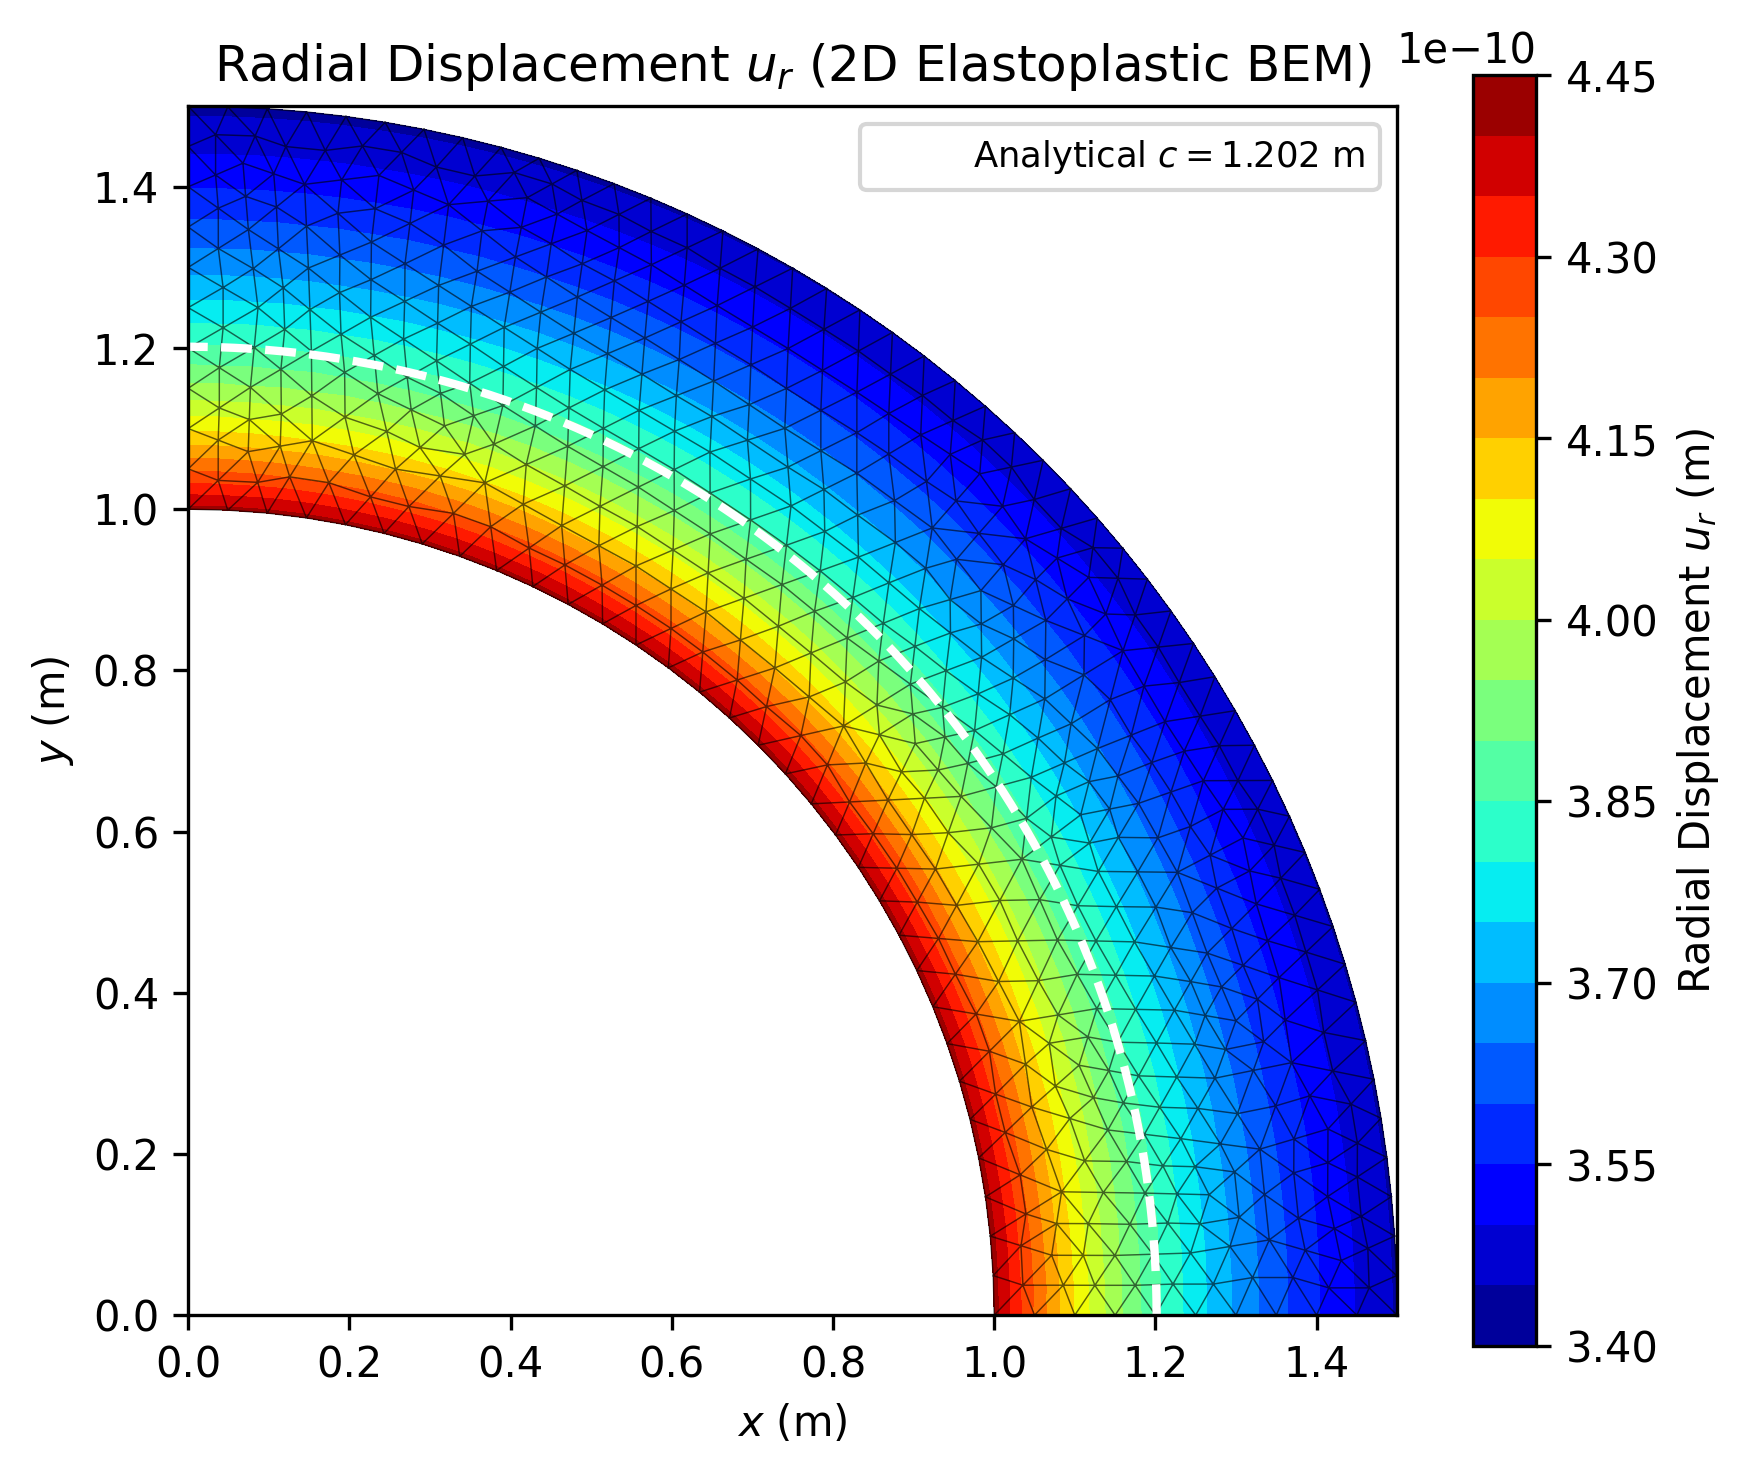

In [ ]:
from IPython.display import Image
Image('displacement_map.png', width=500)

In [ ]:
ls *.png

diagrama_graphviz.png     geometry.png            von_mises_map.png
diagrama_nl_graphviz.png  plastic_strain_map.png
displacement_map.png      result_plot.png


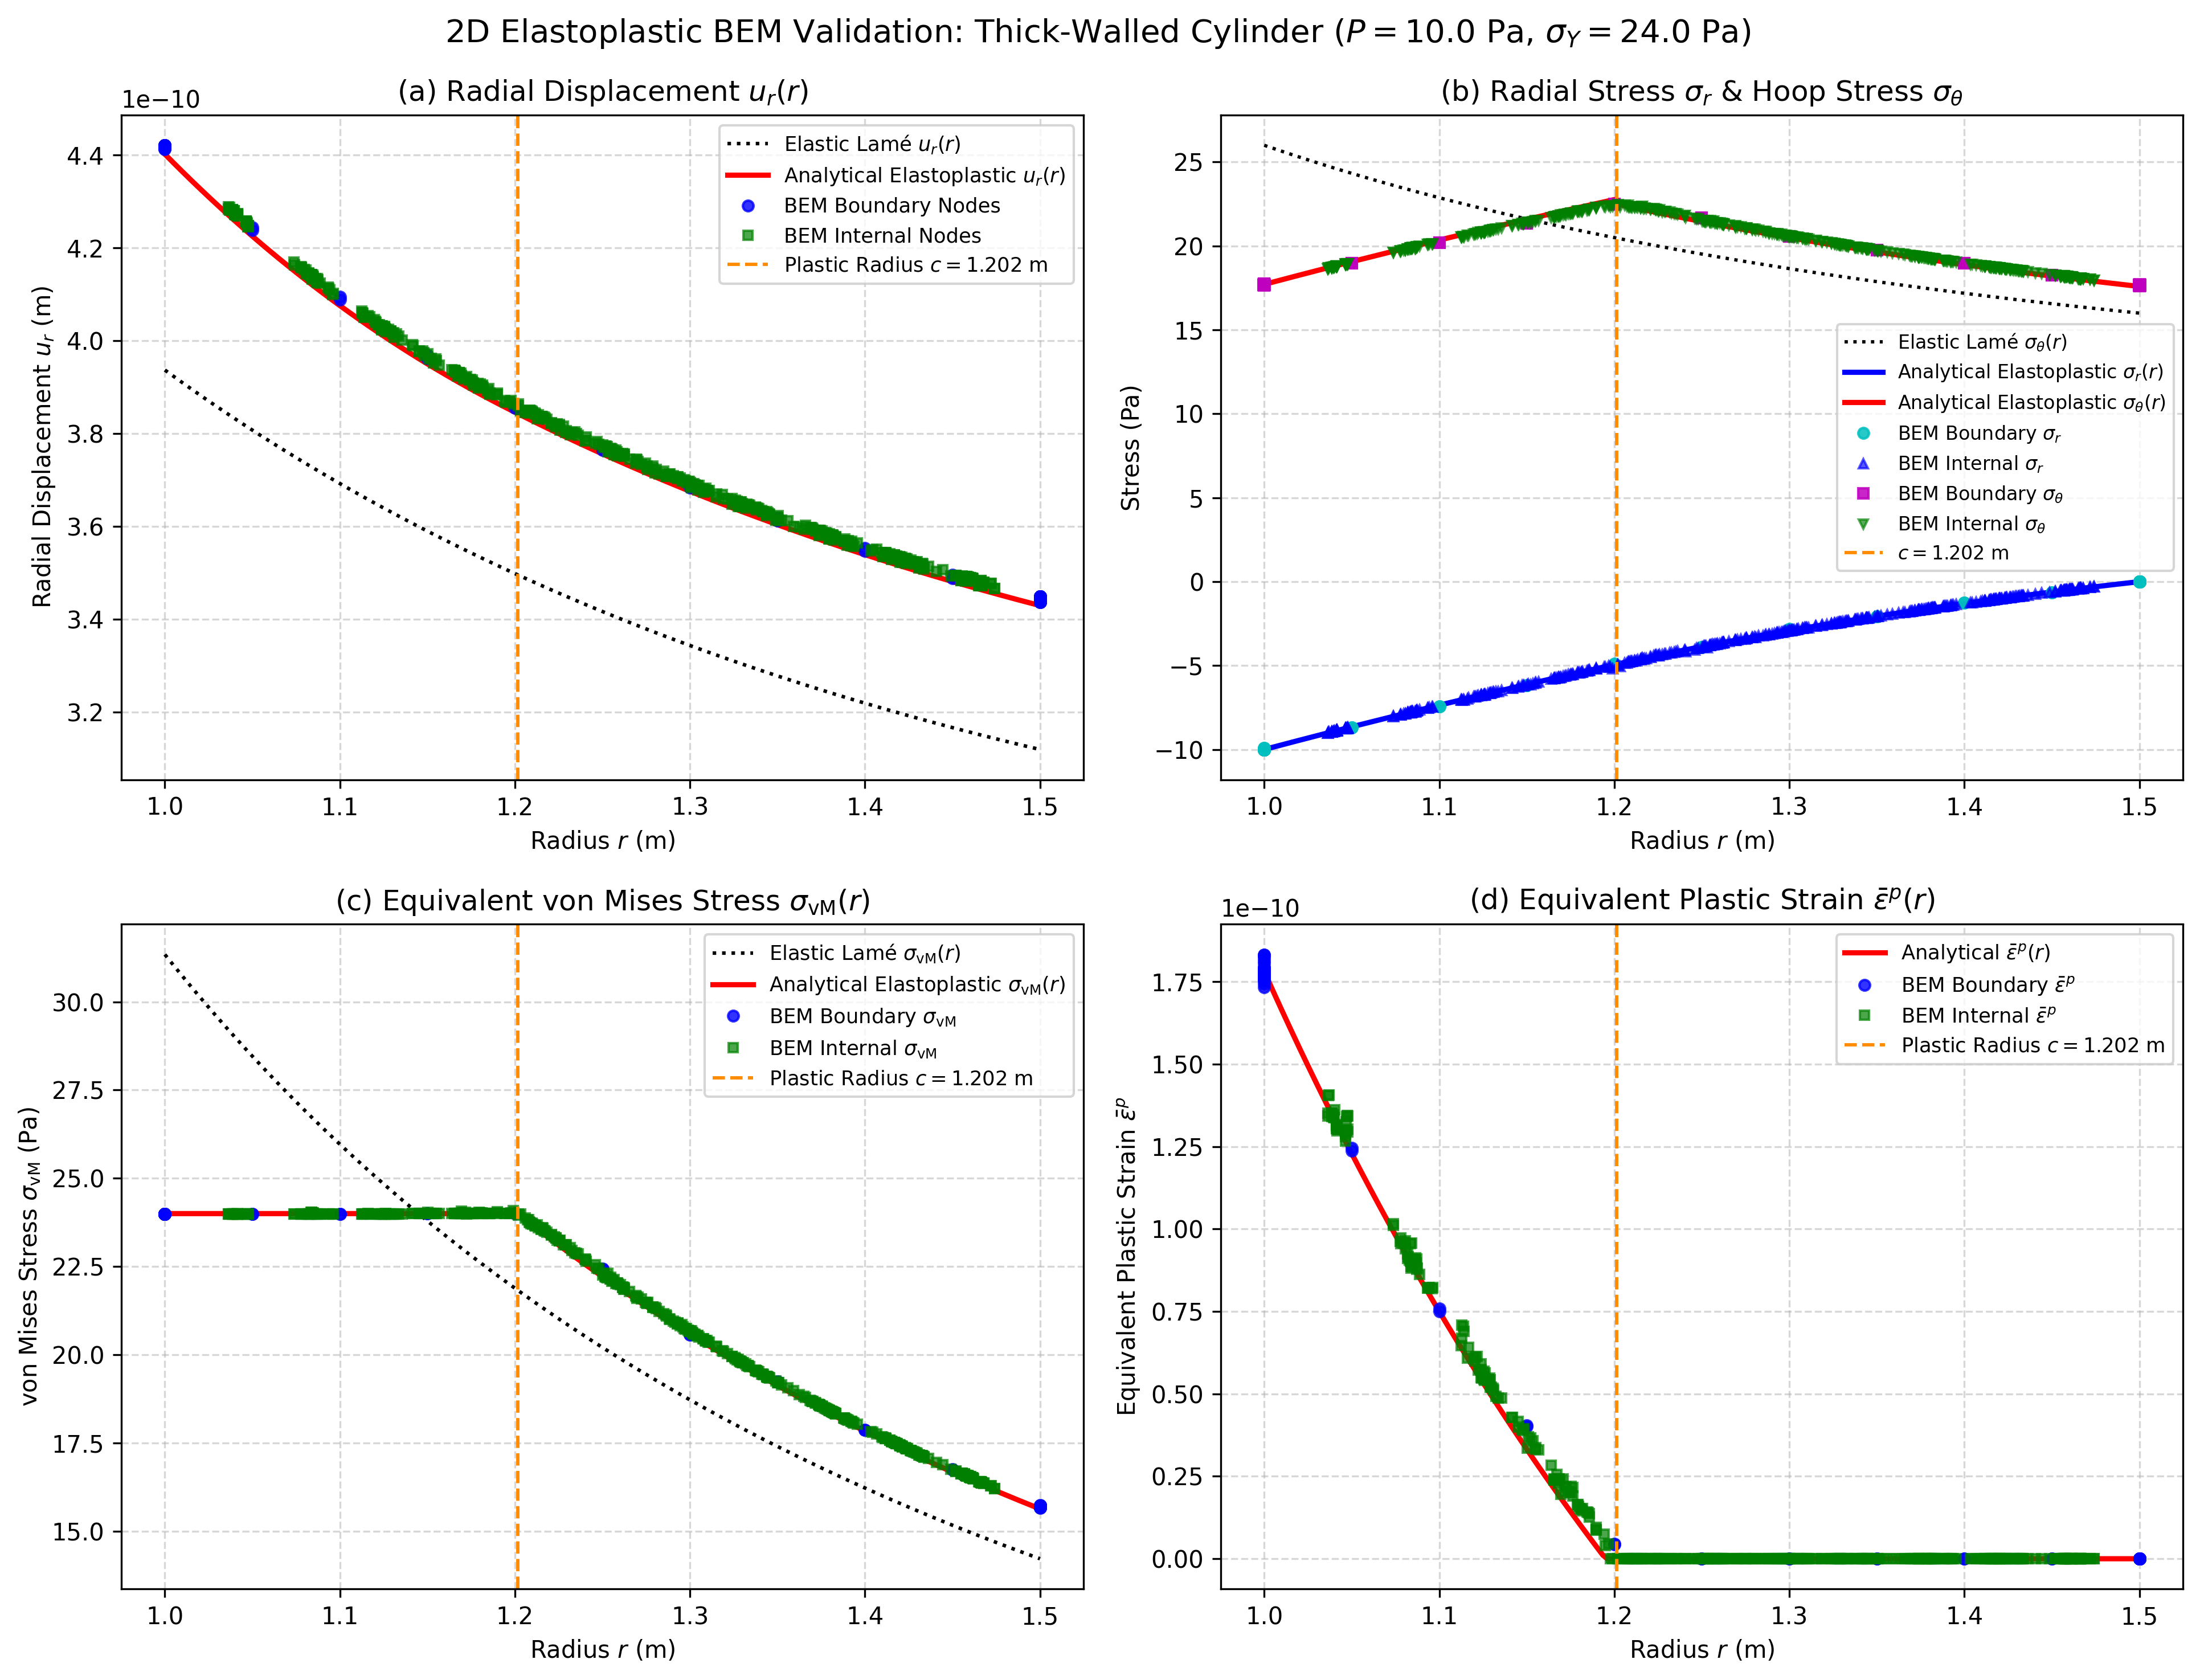

In [ ]:
from IPython.display import Image
Image('result_plot.png', width=500)